# Six Degrees of MoMA: 01 Data and EDA

This notebook downloads MoMA's Exhibition History (1929–1989) and cleans it into three tables:
exhibitions, constituents and participation. It then measures the things that decide the
experimental design:

- curator coverage over time;
- the sparsity of artist–curator relationships;
- how many artist appearances are MoMA debuts, which sets the cold-start share;
- how many exhibited artists MoMA had already collected, which is extra information for
  artists without exhibition history.

Outputs go to `data/processed/` and `results/eda/`.

In [1]:
# Installs anything missing. Colab already has torch, pandas, scikit-learn and matplotlib.
import importlib.util, subprocess, sys

REQUIRED = {"torch": "torch", "torch_geometric": "torch_geometric", "pyarrow": "pyarrow",
            "sentence_transformers": "sentence-transformers", "scipy": "scipy",
            "sklearn": "scikit-learn", "matplotlib": "matplotlib"}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

In [2]:
from pathlib import Path

# On Colab, set USE_DRIVE = True to keep data and results across sessions.
USE_DRIVE = False
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/moma-project")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
RESULTS_DIR = ROOT / "results"
for d in [RAW_DIR, PROCESSED_DIR, RESULTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CFG = {
    # Raw ExhibitionRole values mapped onto node roles; everything else is "other".
    # Institutions listed with a curator role are treated as "other" (organizers).
    "roles": {"artist": ["Artist"], "curator": ["Curator"]},
    "features": {"title_encoder": "minilm",   # minilm | tfidf
                 "title_dim": 32, "top_nationalities": 12,
                 "collection": True},     # MoMA Collection acquisition counts per artist
    "split": {
        "cutoffs": [1950, 1960, 1970, 1980],
        "val_years": 5,       # val targets:  [T - val_years, T)
        "test_years": 10,     # test targets: [T, T + test_years)
        "train_window": 5,    # rolling training targets: [t, t + train_window)
        "train_start": 1932,  # earliest pseudo-cutoff for training snapshots
    },
    "eval": {"ks": [10, 20, 50], "primary_metric": "map@20"},
    "baselines": {
        "recency_tau": 10.0,
        "node2vec": {"dim": 64, "walk_length": 20, "walks_per_node": 10, "window": 4,
                     "p": 1.0, "q": 1.0, "epochs": 2, "num_neg": 5},
    },
    "model": {
        "name": "rgcn",           # rgcn | heteroconv | hgt | sage | gat | mlp
        "curator_mode": "full",   # full | none | shuffled
        "hidden": 64, "layers": 3, "dropout": 0.2, "lr": 0.005, "weight_decay": 1e-4,
        "epochs": 300, "eval_every": 5, "patience": 10,   # patience in evaluation rounds
        "loss": "bpr",            # bpr | bce
        "num_neg": 20,
        "curator_ids": True,      # learned embedding per curator (heterogeneous models)
        "max_group": None,        # subsample group shows above this size (homogeneous graph)
    },
    "seeds": [0, 1, 2, 3, 4],
}

## Core: data loading and cleaning

The CSV has one row per (exhibition, constituent, role) and is cp1252-encoded. MoMA's
collection data adds one row per acquired artwork; only the artist and acquisition date are kept.

- **Exhibitions** are keyed on (number, title, begin date). ExhibitionID is missing for about 430 rows, and
  the number "No#" covers about 50 different exhibitions. `exh_id` is the chronological index.
- **Constituents** without a ConstituentID are keyed by display name.
- **Roles**: `artist`, `curator` (an individual with `ExhibitionRole == "Curator"`) or `other`.

In [3]:
import copy, json, re, time, urllib.request
from dataclasses import dataclass, replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/MuseumofModernArt/exhibitions/master/"
EXHIBITIONS_FILE = "MoMAExhibitions1929to1989.csv"
# MoMA's collection data (73 MB, stored with Git LFS, hence the media URL).
COLLECTION_URL = "https://media.githubusercontent.com/media/MuseumofModernArt/collection/main/"
COLLECTION_FILE = "Artworks.csv"
TABLES = ["exhibitions", "constituents", "participation", "acquisitions"]


def download(raw_dir, force=False):
    for url, name in [(BASE_URL, EXHIBITIONS_FILE), (COLLECTION_URL, COLLECTION_FILE)]:
        dest = raw_dir / name
        if force or not dest.exists():
            print(f"downloading {name}")
            urllib.request.urlretrieve(url + name, dest)


def load_raw(raw_dir):
    return pd.read_csv(raw_dir / EXHIBITIONS_FILE, encoding="cp1252", dtype=str)


def build_exhibitions(raw):
    ex = raw.drop_duplicates("exh_key")[[
        "exh_key", "ExhibitionID", "ExhibitionNumber", "ExhibitionTitle",
        "ExhibitionBeginDate", "ExhibitionEndDate", "ExhibitionSortOrder", "ExhibitionURL",
    ]].copy()
    ex["begin"] = pd.to_datetime(ex["ExhibitionBeginDate"], format="%m/%d/%Y")
    ex["end"] = pd.to_datetime(ex["ExhibitionEndDate"], format="%m/%d/%Y")
    ex["sort_order"] = pd.to_numeric(ex["ExhibitionSortOrder"], errors="coerce")
    ex = ex.sort_values(["begin", "sort_order", "exh_key"]).reset_index(drop=True)
    ex["exh_id"] = np.arange(len(ex))
    ex["year"] = ex["begin"].dt.year + (ex["begin"].dt.day_of_year - 1) / 365.25
    duration = (ex["end"] - ex["begin"]).dt.days
    ex["duration_days"] = duration.where(duration >= 0)
    return ex.rename(columns={
        "ExhibitionID": "source_id", "ExhibitionNumber": "number",
        "ExhibitionTitle": "title", "ExhibitionURL": "url",
    })[["exh_id", "exh_key", "source_id", "number", "title", "begin", "end", "year",
        "duration_days", "url"]]


def build_constituents(rows):
    def first_valid(s):
        s = s.dropna()
        return s.iloc[0] if len(s) else None

    cols = {
        "DisplayName": "name", "ConstituentType": "type", "Nationality": "nationality",
        "Gender": "gender", "ConstituentBeginDate": "birth_year",
        "ConstituentEndDate": "death_year", "WikidataID": "wikidata", "ULANID": "ulan",
    }
    con = rows.groupby("cid")[list(cols)].agg(first_valid).rename(columns=cols).reset_index()
    con["gender"] = con["gender"].str.lower().fillna("unknown")
    nat = con["nationality"]
    con["nationality"] = nat.where(nat != "Nationality unknown").fillna("unknown")
    con["type"] = con["type"].fillna("unknown")
    for col in ["birth_year", "death_year"]:
        year = pd.to_numeric(con[col], errors="coerce")
        con[col] = year.where(year > 0)
    return con


def build_participation(rows, roles):
    raw_role = rows["ExhibitionRole"]
    role = pd.Series("other", index=rows.index)
    role[raw_role.isin(roles["artist"])] = "artist"
    is_curator = raw_role.isin(roles["curator"]) & (rows["ConstituentType"] != "Institution")
    role[is_curator] = "curator"
    part = pd.DataFrame({
        "exh_id": rows["exh_id"].values,
        "cid": rows["cid"].values,
        "role": role.values,
        "raw_role": raw_role.values,
        "press_role": rows["ExhibitionRoleinPressRelease"].values,
    })
    return part.drop_duplicates(["exh_id", "cid", "role"]).reset_index(drop=True)


def clean(raw, roles):
    raw = raw.copy()
    raw["exh_key"] = (raw["ExhibitionNumber"].fillna("") + "|" + raw["ExhibitionTitle"].fillna("")
                      + "|" + raw["ExhibitionBeginDate"].fillna(""))
    exhibitions = build_exhibitions(raw)
    raw["exh_id"] = raw["exh_key"].map(exhibitions.set_index("exh_key")["exh_id"])

    # Rows with no role and no constituent only record that an exhibition happened.
    rows = raw[raw["ExhibitionRole"].notna() & raw["DisplayName"].notna()].copy()
    rows["cid"] = ("moma:" + rows["ConstituentID"]).fillna("name:" + rows["DisplayName"].str.strip())
    constituents = build_constituents(rows)
    participation = build_participation(rows, roles)

    has_curator = participation.loc[participation["role"] == "curator", "exh_id"].unique()
    exhibitions["has_curator"] = exhibitions["exh_id"].isin(has_curator)
    return {"exhibitions": exhibitions, "constituents": constituents,
            "participation": participation}


def load_acquisitions(raw_dir):
    """One row per (artwork, artist) acquired by MoMA, with the acquisition date. Artists are
    keyed like exhibition constituents ("moma:<ConstituentID>"), which is the same id space."""
    works = pd.read_csv(raw_dir / COLLECTION_FILE, dtype=str,
                        usecols=["ObjectID", "ConstituentID", "DateAcquired"])
    works["acquired"] = pd.to_datetime(works["DateAcquired"], errors="coerce")
    works = works.dropna(subset=["ConstituentID", "acquired"])
    works = works.assign(cid=works["ConstituentID"].str.split(",")).explode("cid")
    works["cid"] = "moma:" + works["cid"].str.strip()
    return works[["cid", "ObjectID", "acquired"]].rename(columns={"ObjectID": "object_id"}) \
        .drop_duplicates().reset_index(drop=True)


def load_tables(force=False):
    """Cleaned tables from data/processed, rebuilding them from the raw CSV if needed."""
    if not force and all((PROCESSED_DIR / f"{n}.parquet").exists() for n in TABLES):
        return {n: pd.read_parquet(PROCESSED_DIR / f"{n}.parquet") for n in TABLES}
    download(RAW_DIR)
    tables = clean(load_raw(RAW_DIR), CFG["roles"])
    tables["acquisitions"] = load_acquisitions(RAW_DIR)
    for name, df in tables.items():
        df.to_parquet(PROCESSED_DIR / f"{name}.parquet", index=False)
    return tables

### Integer-indexed dataset

Artists and curators have separate node index spaces. A person who both exhibited and curated
appears once in each; both keep `cid` so they can be merged back into one person when needed.

`with_shuffled_curators` is the shuffle ablation. It permutes curator→exhibition assignments
within each decade, so every curator keeps their number of exhibitions and every exhibition
keeps its number of curators.

In [4]:
@dataclass
class MomaData:
    exhibitions: pd.DataFrame    # indexed by exh_id (chronological)
    artists: pd.DataFrame        # indexed by artist node id
    curators: pd.DataFrame       # indexed by curator node id
    artist_edges: pd.DataFrame   # columns exh_id, artist
    curator_edges: pd.DataFrame  # columns exh_id, curator
    acquisitions: pd.DataFrame   # columns artist, year: collection artworks by acquisition date

    @classmethod
    def from_tables(cls, tables):
        ex = tables["exhibitions"].set_index("exh_id", drop=False).sort_index()
        con = tables["constituents"].set_index("cid")
        part = tables["participation"]

        def role_nodes(role):
            edges = part[part["role"] == role][["exh_id", "cid"]]
            cids = np.sort(edges["cid"].unique())
            nodes = con.loc[cids].reset_index()
            node_of = pd.Series(np.arange(len(cids)), index=cids)
            edges = pd.DataFrame({"exh_id": edges["exh_id"].to_numpy(),
                                  role: node_of.loc[edges["cid"]].to_numpy()})
            return nodes, edges.sort_values(["exh_id", role]).reset_index(drop=True)

        artists, artist_edges = role_nodes("artist")
        curators, curator_edges = role_nodes("curator")

        acq = tables["acquisitions"]
        artist_of = pd.Series(artists.index, index=artists["cid"])
        acq = acq[acq["cid"].isin(artist_of.index)]
        date = acq["acquired"].dt
        acquisitions = pd.DataFrame({
            "artist": artist_of.loc[acq["cid"]].to_numpy(),
            "year": (date.year + (date.day_of_year - 1) / 365.25).to_numpy(),
        }).sort_values("year", ignore_index=True)
        return cls(ex, artists, curators, artist_edges, curator_edges, acquisitions)

    @property
    def num_artists(self):
        return len(self.artists)

    @property
    def num_curators(self):
        return len(self.curators)

    @property
    def num_exhibitions(self):
        return len(self.exhibitions)

    def with_shuffled_curators(self, seed):
        rng = np.random.default_rng(seed)
        edges = self.curator_edges.copy()
        decade = (self.exhibitions.loc[edges["exh_id"], "begin"].dt.year // 10).to_numpy()
        exh = edges["exh_id"].to_numpy().copy()
        for d in np.unique(decade):
            idx = np.flatnonzero(decade == d)
            exh[idx] = exh[rng.permutation(idx)]
        edges["exh_id"] = exh
        # A permutation can rarely pair a curator with the same exhibition twice.
        edges = edges.drop_duplicates().sort_values(["exh_id", "curator"]).reset_index(drop=True)
        return replace(self, curator_edges=edges)

## Clean the raw data

In [5]:
download(RAW_DIR)
raw = load_raw(RAW_DIR)
print(raw.shape)
raw["ExhibitionRole"].value_counts(dropna=False)

(34558, 28)


ExhibitionRole
Artist               32537
Curator               1495
Installer              150
NaN                    134
Competition Judge      132
Designer                66
Arranger                31
Preparer                13
Name: count, dtype: int64

In [6]:
tables = load_tables(force=True)
data = MomaData.from_tables(tables)
for name, df in tables.items():
    print(f"{name}: {len(df)} rows")
tables["participation"]["role"].value_counts()

exhibitions: 1787 rows
constituents: 11607 rows
participation: 34422 rows
acquisitions: 170827 rows


role
artist     32537
curator     1483
other        402
Name: count, dtype: int64

In [7]:
# Sanity checks on a small synthetic example: keys, roles, dates.
cols = ["ExhibitionID", "ExhibitionNumber", "ExhibitionTitle", "ExhibitionBeginDate",
        "ExhibitionEndDate", "ExhibitionSortOrder", "ExhibitionURL", "ExhibitionRole",
        "ExhibitionRoleinPressRelease", "ConstituentID", "ConstituentType", "DisplayName",
        "Nationality", "Gender", "ConstituentBeginDate", "ConstituentEndDate", "WikidataID",
        "ULANID"]
toy = pd.DataFrame([dict(zip(cols, r)) for r in [
    # Two "No#" exhibitions that share a number but are distinct.
    (None, "No#", "B", "3/1/1950", "4/1/1950", "1", None, "Curator", "Director", "1",
     "Individual", "Curator One", "American", "Male", "1900", "1980", None, None),
    (None, "No#", "B", "3/1/1950", "4/1/1950", "1", None, "Artist", "Artist", "2",
     "Individual", "Artist Two", None, "male", "1890", None, None, None),
    ("7", "No#", "A", "1/5/1940", None, "1", None, "Artist", "Artist", None,
     "Individual", "Nameless Artist", None, None, None, None, None, None),
    ("7", "No#", "A", "1/5/1940", None, "1", None, "Curator", "Organizer", "3",
     "Institution", "Some Org", None, None, None, None, None, None),
    # Exhibition-only row (no participant) with an end date before its begin date.
    ("8", "12", "C", "6/1/1960", "5/1/1960", "1", None, None, None, None,
     None, None, None, None, None, None, None, None),
]], columns=cols, dtype=object)
t = clean(toy, CFG["roles"])
assert list(t["exhibitions"]["title"]) == ["A", "B", "C"]
assert t["exhibitions"]["duration_days"].isna().tolist() == [True, False, True]
assert list(t["exhibitions"]["has_curator"]) == [False, True, False]
assert t["participation"].set_index("cid")["role"].to_dict() == {
    "moma:1": "curator", "moma:2": "artist", "name:Nameless Artist": "artist", "moma:3": "other"}

# And on the real data.
assert tables["exhibitions"]["begin"].notna().all()
assert not tables["participation"].duplicated(["exh_id", "cid", "role"]).any()
print("cleaning checks passed")

cleaning checks passed


## Coverage and sparsity

In [8]:
ex = data.exhibitions
ae, ce = data.artist_edges, data.curator_edges
part = tables["participation"]
decade = ex["begin"].dt.year // 10 * 10

# Debut vs returning artist appearances.
ae_years = ae.assign(year=ex.loc[ae["exh_id"], "begin"].dt.year.to_numpy())
ae_years["debut"] = ae_years["exh_id"] == ae_years.groupby("artist")["exh_id"].transform("min")
ae_years["decade"] = ae_years["year"] // 10 * 10

artists_per_exh = ae.groupby("exh_id").size().reindex(ex.index, fill_value=0)
curators_per_exh = ce.groupby("exh_id").size().reindex(ex.index, fill_value=0)
exh_per_curator = ce.groupby("curator").size()
exh_per_artist = ae.groupby("artist").size()

by_decade = pd.DataFrame({
    "exhibitions": ex.groupby(decade).size(),
    "frac_with_curator": ex.groupby(decade)["has_curator"].mean(),
    "mean_curators": curators_per_exh.groupby(decade).mean(),
    "mean_artists": artists_per_exh.groupby(decade).mean(),
    "artist_appearances": ae_years.groupby("decade").size(),
    "frac_debut_appearances": ae_years.groupby("decade")["debut"].mean(),
    "distinct_curators": ce.groupby(decade.loc[ce["exh_id"]].to_numpy())["curator"].nunique(),
}).fillna(0)
(RESULTS_DIR / "eda").mkdir(exist_ok=True)
by_decade.to_csv(RESULTS_DIR / "eda" / "by_decade.csv")
by_decade.round(3)

,exhibitions,frac_with_curator,mean_curators,mean_artists,artist_appearances,frac_debut_appearances,distinct_curators
1920,2,0.500,0.500,11.500,23,1.000,1
1930,135,0.385,0.541,25.852,3490,0.576,30
1940,370,0.400,0.530,18.311,6775,0.425,92
1950,232,0.664,0.797,26.591,6169,0.383,40
1960,301,0.721,0.934,17.502,5268,0.280,81
1970,428,0.846,0.977,13.633,5835,0.259,84
1980,319,0.846,1.031,15.602,4977,0.204,87


In [9]:
# Artist-curator relationships, and a first look at the curator signal: among returning artists
# in curated exhibitions, how many previously exhibited with one of that exhibition's curators?
shared = ae.merge(ce, on="exh_id")                                  # (exh, artist, curator)
pair_counts = shared.groupby(["artist", "curator"]).size()
prior = shared.merge(shared, on=["artist", "curator"], suffixes=("", "_prev"))
prior = prior[prior["exh_id_prev"] < prior["exh_id"]][["exh_id", "artist"]].drop_duplicates()
returning = ae[ae["exh_id"].isin(ce["exh_id"])].merge(
    ae_years[~ae_years["debut"]][["exh_id", "artist"]], on=["exh_id", "artist"])

summary = {
    "exhibitions": len(ex),
    "exhibitions_with_curator": int(ex["has_curator"].sum()),
    "exhibitions_without_artists": int((artists_per_exh == 0).sum()),
    "artists": data.num_artists,
    "curators": data.num_curators,
    "artist_edges": len(ae),
    "curator_edges": len(ce),
    "artist_curator_overlap": len(set(data.artists["cid"]) & set(data.curators["cid"])),
    "other_role_rows": part[part["role"] == "other"]["raw_role"].value_counts().to_dict(),
    "median_artists_per_exhibition": float(artists_per_exh[artists_per_exh > 0].median()),
    "frac_artists_single_exhibition": float((exh_per_artist == 1).mean()),
    "median_exhibitions_per_curator": float(exh_per_curator.median()),
    "top_curators": {data.curators.loc[c, "name"]: int(n)
                     for c, n in exh_per_curator.nlargest(10).items()},
    "artist_curator_pairs": len(pair_counts),
    "artist_curator_density": len(pair_counts) / (data.num_artists * data.num_curators),
    "frac_pairs_repeated": float((pair_counts >= 2).mean()),
    "frac_returning_with_prior_curator": len(prior) / max(len(returning), 1),
    "artists_in_collection": int(data.acquisitions["artist"].nunique()),
    "acquisitions_before_1990": int((data.acquisitions["year"] < 1990).sum()),
}
with open(RESULTS_DIR / "eda" / "summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=float)
summary

{'exhibitions': 1787,
 'exhibitions_with_curator': 1204,
 'exhibitions_without_artists': 252,
 'artists': 11273,
 'curators': 316,
 'artist_edges': 32537,
 'curator_edges': 1483,
 'artist_curator_overlap': 55,
 'other_role_rows': {'Installer': 150,
  'Competition Judge': 132,
  'Designer': 66,
  'Arranger': 31,
  'Preparer': 13,
  'Curator': 10},
 'median_artists_per_exhibition': 5.0,
 'frac_artists_single_exhibition': 0.6723143794908187,
 'median_exhibitions_per_curator': 1.0,
 'top_curators': {'William S. Lieberman': 94,
  'John Szarkowski': 80,
  'Barbara London': 78,
  'Riva Castleman': 61,
  'Arthur Drexler': 60,
  'Dorothy C. Miller': 40,
  'William S. Rubin': 38,
  'Alfred H. Barr, Jr.': 38,
  'Bernice Rose': 34,
  'Edward Steichen': 33},
 'artist_curator_pairs': 26761,
 'artist_curator_density': 0.007512348874368801,
 'frac_pairs_repeated': 0.14248346474346998,
 'frac_returning_with_prior_curator': 0.4668929303278688,
 'artists_in_collection': 4423,
 'acquisitions_before_1990':

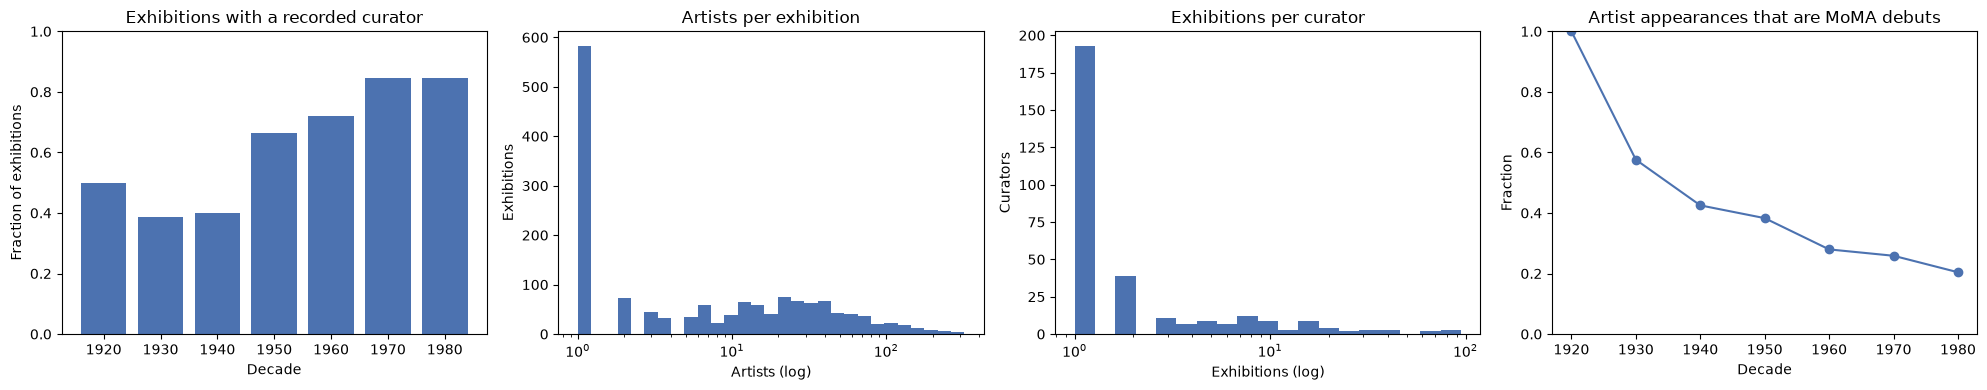

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

ax = axes[0]
ax.bar(by_decade.index.astype(str), by_decade["frac_with_curator"], color="#4c72b0")
ax.set_ylim(0, 1)
ax.set(title="Exhibitions with a recorded curator", xlabel="Decade",
       ylabel="Fraction of exhibitions")

ax = axes[1]
counts = artists_per_exh[artists_per_exh > 0]
ax.hist(counts, bins=np.logspace(0, np.log10(counts.max() + 1), 30), color="#4c72b0")
ax.set_xscale("log")
ax.set(title="Artists per exhibition", xlabel="Artists (log)", ylabel="Exhibitions")

ax = axes[2]
ax.hist(exh_per_curator, bins=np.logspace(0, np.log10(exh_per_curator.max() + 1), 20),
        color="#4c72b0")
ax.set_xscale("log")
ax.set(title="Exhibitions per curator", xlabel="Exhibitions (log)", ylabel="Curators")

ax = axes[3]
ax.plot(by_decade.index, by_decade["frac_debut_appearances"], marker="o", color="#4c72b0")
ax.set_ylim(0, 1)
ax.set(title="Artist appearances that are MoMA debuts", xlabel="Decade", ylabel="Fraction")

fig.tight_layout()
fig.savefig(RESULTS_DIR / "eda" / "eda_overview.png", dpi=150)
plt.show()

### Collection acquisitions before a debut

For artists whose first MoMA exhibition falls in a test decade, how many already had works in
the collection when the decade began? Those acquisitions are known at prediction time, so they
can help rank artists who have no exhibition history.

In [11]:
acq = data.acquisitions
first_exh = ae_years.groupby("artist")["year"].min()
rows = []
for cutoff in CFG["split"]["cutoffs"]:
    debuts = first_exh[(first_exh >= cutoff) & (first_exh < cutoff + 10)].index
    before = acq[(acq["year"] < cutoff) & acq["artist"].isin(debuts)]
    rows.append({"test decade": f"{cutoff}s", "debuting artists": len(debuts),
                 "with works acquired before the decade": before["artist"].nunique(),
                 "share": before["artist"].nunique() / len(debuts)})
collection_coverage = pd.DataFrame(rows)
collection_coverage.to_csv(RESULTS_DIR / "eda" / "collection_before_debut.csv", index=False)
collection_coverage.round(3)

,test decade,debuting artists,with works acquired before the decade,share
0,1950s,2362,52,0.022
1,1960s,1473,70,0.048
2,1970s,1509,184,0.122
3,1980s,1016,107,0.105
